# 06 · Kuantum çekirdeğini kuantum algoritmalarıyla çözmek (simülatörde)
*Makale: Bölüm 3, Şekil 4d.*

05'teki CASCI enerjisini bu sefer bir **kuantum bilgisayarın yapacağı gibi** hesaplıyoruz:

1. Aktif uzay Hamiltoniyenini fermiyon operatörlerine, sonra **Jordan–Wigner** dönüşümüyle **qubit**
   operatörlerine çeviriyoruz: $H = \sum_i h_i P_i$ ($P_i$: Pauli dizileri). $N$ orbital için $2N$ qubit gerekiyor.
2. **VQE:** Yakın vadeli, değişkenli yöntem. Makale büyük sistemlerde sorunlu olduğunu belirtiyor.
3. **QPE (kuantum faz tahmini):** Makalenin hedeflediği, hata düzeltmeli bilgisayar algoritması.
   Bir başlangıç durumu $|\psi\rangle$ hazırlanıyor, $e^{-iHt}$ uygulanıyor ve faz ölçülüyor.
   Doğru enerjiyi bulma olasılığı $|\langle\psi|\Psi_0\rangle|^2$ örtüşmesine bağlı.
4. **Trotter:** Gerçek donanımda $e^{-iHt}$ tam uygulanamıyor; Pauli terimlerinin üstellerinin çarpımına bölünüyor.

Hepsi klasik **durum vektörü simülasyonu**. Bu yaklaşım ~25–30 qubit'e kadar işliyor.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
from qfe import config, store
from qfe.plotting import C, LEG, LEG_TR
import numpy as np, matplotlib.pyplot as plt
# Ön ayar: "test" (hızlı kontrol), "demo" (ekibe gösterim), "standart" (daha güvenilir)
config.set_preset(os.environ.get("QFE_PRESET", "demo"))
print("Aktif ön ayar:", config.preset_name())

Aktif ön ayar: test


In [2]:
from qfe import qmmm, quantum
from qfe.plotting import SERIES
pools = {leg: (lambda d: (d["X"], d["B"]))(store.load_npz(f"pool_{leg}.npz")) for leg in ["complex"]}
reg = qmmm.QMRegion("complex")
fr = reg.frame(pools["complex"][0][0], pools["complex"][1][0])
mf = qmmm.hf_in_field(fr, reg.guest_symbols())
ncas, nel = config.P()["cas"]
nq = 2 * ncas
h1, h2, ecore = quantum.active_space_integrals(mf, ncas, nel)
qop = quantum.qubit_hamiltonian(h1, h2, ecore)
print(f"CAS({nel},{ncas}) → {nq} qubit, {len(qop.terms)} Pauli terimi")
for term, c in list(qop.terms.items())[:6]:
    print("  ", "".join(f"{p}{q}" for q, p in term) or "I", f"{c.real:+.5f}")

CAS(4,4) → 8 qubit, 361 Pauli terimi
   I -268.67062
   Z0 +0.24805
   Z1 +0.24805
   Z2 +0.25650
   Z3 +0.25650
   Z4 -0.01460


### 1) Klasik referans: tam köşegenleştirme = CASCI olmalı

In [3]:
from pyscf import mcscf
HN, idx, hf_pos, Hs = quantum.number_sector(qop, nq, nel)
w, v = quantum.exact_ground(HN)
mc = mcscf.CASCI(mf, ncas, nel); mc.verbose = 0; e_casci = mc.kernel()[0]
print(f"{nel}-elektron alt uzayının boyutu: {len(HN)} (tam Hilbert uzayı 2^{nq} = {2**nq})")
print(f"Qubit Hamiltoniyeni özdeğeri : {w[0]:.8f} Ha")
print(f"PySCF CASCI                  : {e_casci:.8f} Ha   fark = {abs(w[0]-e_casci):.1e}")
print(f"HF başlangıç durumu örtüşmesi |<HF|Ψ0>|² = {abs(v[hf_pos,0])**2:.5f}")

4-elektron alt uzayının boyutu: 70 (tam Hilbert uzayı 2^8 = 256)
Qubit Hamiltoniyeni özdeğeri : -269.81529944 Ha
PySCF CASCI                  : -269.81529944 Ha   fark = 1.1e-13
HF başlangıç durumu örtüşmesi |<HF|Ψ0>|² = 0.99993


### 2) VQE (UCCSD ansatz) — gürültüsüz ve atış gürültülü

[süre] 06_vqe: 248.7 s
VQE (gürültüsüz) : -269.81529944 Ha, hata 0.0000 mHa, 14 parametre, 1257 enerji ölçümü
VQE (2000 atış)  : -269.81487815 Ha, hata 0.4213 mHa, 96 enerji ölçümü


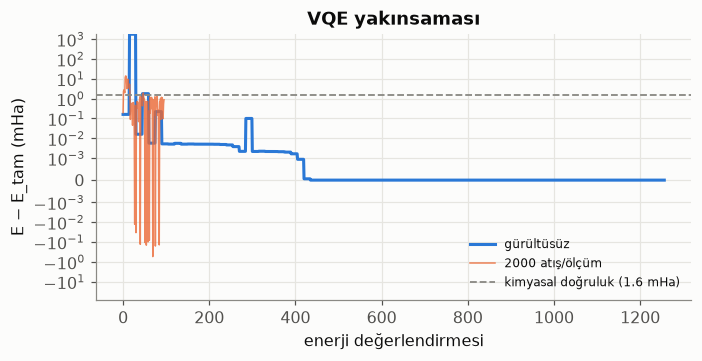

In [4]:
with store.timed("06_vqe"):
    vq = quantum.vqe_uccsd(qop, nq, nel)
    vq_noisy = quantum.vqe_uccsd(qop, nq, nel, shots=2000, maxiter=300)
print(f"VQE (gürültüsüz) : {vq['energy']:.8f} Ha, hata {1000*(vq['energy']-w[0]):.4f} mHa, {vq['n_params']} parametre, {vq['n_evals']} enerji ölçümü")
print(f"VQE (2000 atış)  : {vq_noisy['energy']:.8f} Ha, hata {1000*(vq_noisy['energy']-w[0]):.4f} mHa, {vq_noisy['n_evals']} enerji ölçümü")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(1000 * (vq["trace"] - w[0]), color=C["blue"], label="gürültüsüz")
ax.plot(1000 * (vq_noisy["trace"] - w[0]), color=C["orange"], lw=1, alpha=0.8, label="2000 atış/ölçüm")
ax.axhline(1.6, color=C["muted"], ls="--", lw=1.2, label="kimyasal doğruluk (1.6 mHa)")
ax.set_yscale("symlog", linthresh=1e-3); ax.set_xlabel("enerji değerlendirmesi"); ax.set_ylabel("E − E_tam (mHa)")
ax.set_title("VQE yakınsaması"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Not:** Gerçek donanımda her "enerji değerlendirmesi" binlerce devre çalıştırması (atış) demek.
Atış gürültüsü, optimizasyonu ve son doğruluğu sınırlıyor. Makalenin VQE yerine QPE'yi tercih
etmesinin bir nedeni de bu.

### 3) Kuantum faz tahmini (QPE) — devre simülasyonu

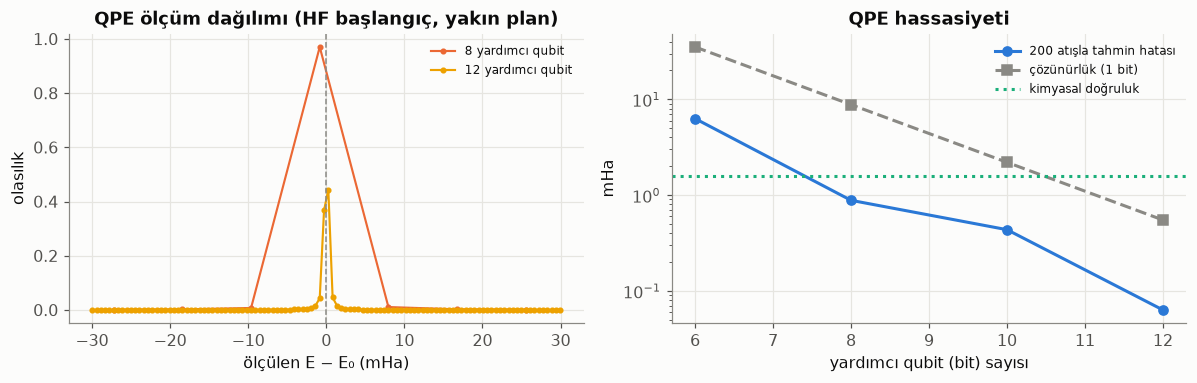

In [5]:
psi_hf = np.zeros(len(HN)); psi_hf[hf_pos] = 1.0
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
errs = []
for k, bits in enumerate([6, 8, 10, 12]):
    q = quantum.qpe_simulate(HN, psi_hf, bits)
    e_est, _ = quantum.qpe_shots(q, 200, seed=k)
    errs.append((bits, abs(e_est - w[0]), q["resolution"]))
    if bits in (8, 12):
        m = (q["energies"] > w[0] - 0.03) & (q["energies"] < w[0] + 0.03)
        axs[0].plot(1000 * (q["energies"][m] - w[0]), q["prob"][m], color=SERIES[k % 4], lw=1.4,
                    marker="o", ms=3, label=f"{bits} yardımcı qubit")
axs[0].axvline(0, color=C["muted"], ls="--", lw=1)
axs[0].set_xlabel("ölçülen E − E₀ (mHa)"); axs[0].set_ylabel("olasılık"); axs[0].set_title("QPE ölçüm dağılımı (HF başlangıç, yakın plan)")
axs[0].legend(fontsize=8)
b, e, r_ = zip(*errs)
axs[1].semilogy(b, np.array(e) * 1000, marker="o", color=C["blue"], label="200 atışla tahmin hatası")
axs[1].semilogy(b, np.array(r_) * 1000, marker="s", ls="--", color=C["muted"], label="çözünürlük (1 bit)")
axs[1].axhline(1.6, color=C["aqua"], ls=":", label="kimyasal doğruluk")
axs[1].set_xlabel("yardımcı qubit (bit) sayısı"); axs[1].set_ylabel("mHa"); axs[1].set_title("QPE hassasiyeti")
axs[1].legend(fontsize=8); plt.tight_layout(); plt.show()

Her ek bit hassasiyeti ~2 kat artırıyor ama gereken evrim süresini ($U^{2^k}$) de 2 kat uzatıyor.
Makaledeki kapı sayılarının ($10^{9}$–$10^{13}$ Toffoli) bu kadar büyük olmasının nedeni bu.

### 4) Trotter hatası: $e^{-iHt}$'yi kapılarla yaklaşık uygulamak

[süre] 06_trotter: 1.0 s


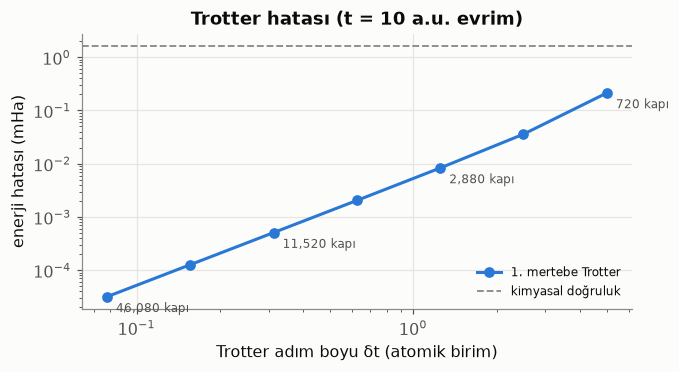

In [6]:
psi0 = np.zeros(2 ** nq, complex); psi0[idx] = v[:, 0]
t_total = 10.0
steps = [2, 4, 8, 16, 32, 64, 128]
with store.timed("06_trotter"):
    tr1 = quantum.trotter_phase_error(qop, nq, psi0, w[0], t_total, steps, order=1)
fig, ax = plt.subplots(figsize=(6.3, 3.5))
ax.loglog([t_total / t["steps"] for t in tr1], [1000 * t["error"] + 1e-12 for t in tr1], marker="o", color=C["blue"], label="1. mertebe Trotter")
for t in tr1[::2]:
    ax.annotate(f"{t['n_exponentials']:,} kapı", (t_total / t["steps"], 1000 * t["error"]), textcoords="offset points",
                xytext=(6, -10), fontsize=8, color=C["ink2"])
ax.axhline(1.6, color=C["muted"], ls="--", lw=1.2, label="kimyasal doğruluk")
ax.set_xlabel("Trotter adım boyu δt (atomik birim)"); ax.set_ylabel("enerji hatası (mHa)")
ax.set_title(f"Trotter hatası (t = {t_total:.0f} a.u. evrim)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Adım küçüldükçe hata hızla düşüyor ama **kapı sayısı** ters orantılı olarak artıyor. Bu küçük ve zayıf
korelasyonlu sistemde hata zaten küçük. Aktif uzay büyüdükçe Hamiltoniyenin normu λ büyüyor ve aynı
doğruluk için çok daha küçük adım gerekiyor (bkz. 07, kaynak tahmini). Makale bu Trotter hatasını
36 qubit'e kadar GPU statevector simülasyonuyla ölçüp daha büyük sistemlere ekstrapole ediyor (ref. 30).

### 5) Başlangıç durumu örtüşmesi — aktif uzay büyüdükçe (makale Şekil 4d)

[süre] 06_ortusme_taramasi: 6.3 s


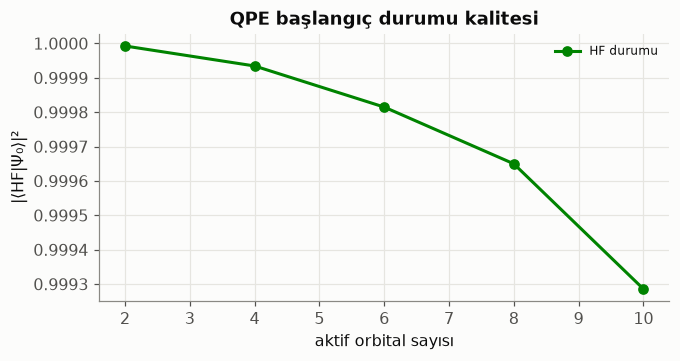

CAS(2,2):  4 qubit,         4 determinant, örtüşme 1.0000, klasik süre 0.96 s
CAS(4,4):  8 qubit,        36 determinant, örtüşme 0.9999, klasik süre 1.13 s
CAS(6,6): 12 qubit,       400 determinant, örtüşme 0.9998, klasik süre 1.29 s
CAS(8,8): 16 qubit,     4,900 determinant, örtüşme 0.9996, klasik süre 1.38 s
CAS(10,10): 20 qubit,    63,504 determinant, örtüşme 0.9993, klasik süre 1.50 s


In [7]:
with store.timed("06_ortusme_taramasi"):
    ov = quantum.hf_overlap_scan(mf, config.P()["overlap_scan"])
store.save_json("quantum.json", {"overlap_scan": ov})
fig, ax = plt.subplots(figsize=(6.3, 3.4))
ax.plot([o["n_orb"] for o in ov], [o["overlap_hf"] for o in ov], marker="o", color=C["green"], label="HF durumu")
ax.set_xlabel("aktif orbital sayısı"); ax.set_ylabel("|⟨HF|Ψ₀⟩|²"); ax.set_title("QPE başlangıç durumu kalitesi")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
for o in ov:
    print(f"CAS({o['n_orb']},{o['n_orb']}): {o['n_qubits']:2d} qubit, {o['n_determinants']:>9,d} determinant, "
          f"örtüşme {o['overlap_hf']:.4f}, klasik süre {o['seconds']:.2f} s")

**Yorum:**
- Örtüşme, aktif uzay büyüdükçe düşüyor. Makalede Ru sistemi için 30 orbitalde HF örtüşmesi ~0.73'e iniyor;
  daha iyi başlangıç durumlarıyla (MPS, Slater determinant toplamı) ~0.9–0.97'ye çıkıyor.
- **Determinant sayısı üstel büyüyor.** ~18 orbitalden sonra klasik tam çözüm (FCI) laptopta imkânsız hale
  geliyor. Bu noktadan sonra **DMRG (HPC)** ya da **kuantum bilgisayar** gerekiyor.

### 6) Gerçek kuantum donanımına köprü
Aşağıdaki hücre Hamiltoniyeni Qiskit'in okuyabileceği bir JSON dosyasına yazıyor. IBM Quantum'un ücretsiz
planında küçük bir örnek (ör. CAS(2,2) → 4 qubit) için tahmin yapılabilir (bkz. README).

In [8]:
import json
small = quantum.qubit_hamiltonian(*quantum.active_space_integrals(mf, 2, 2))
for name, op, n in [("H_cas22_4qubit.json", small, 4), (f"H_cas{nel}{ncas}_{nq}qubit.json", qop, nq)]:
    pl = [(lab, [c.real, c.imag]) for lab, c in quantum.pauli_list(op, n)]
    (store.path(name)).write_text(json.dumps(pl))
    print("yazıldı:", store.path(name), f"({len(pl)} terim)")

yazıldı: /home/claude/qb/results/test/H_cas22_4qubit.json (27 terim)
yazıldı: /home/claude/qb/results/test/H_cas44_8qubit.json (361 terim)
